In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import pandas as pd 
from sklearn.metrics import (
    normalized_mutual_info_score
)
from scipy.optimize import linear_sum_assignment
import sys
sys.path.append('../../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = "glpk"

In [2]:
with open('../../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    clustered_nodes = pickle.load(f)

with open('../../../Coarse_graining_result/clustered_nodes_c20_s91_pq1.pkl', 'rb') as f:
    clustered_nodes2 = pickle.load(f)

NMI = 0.776


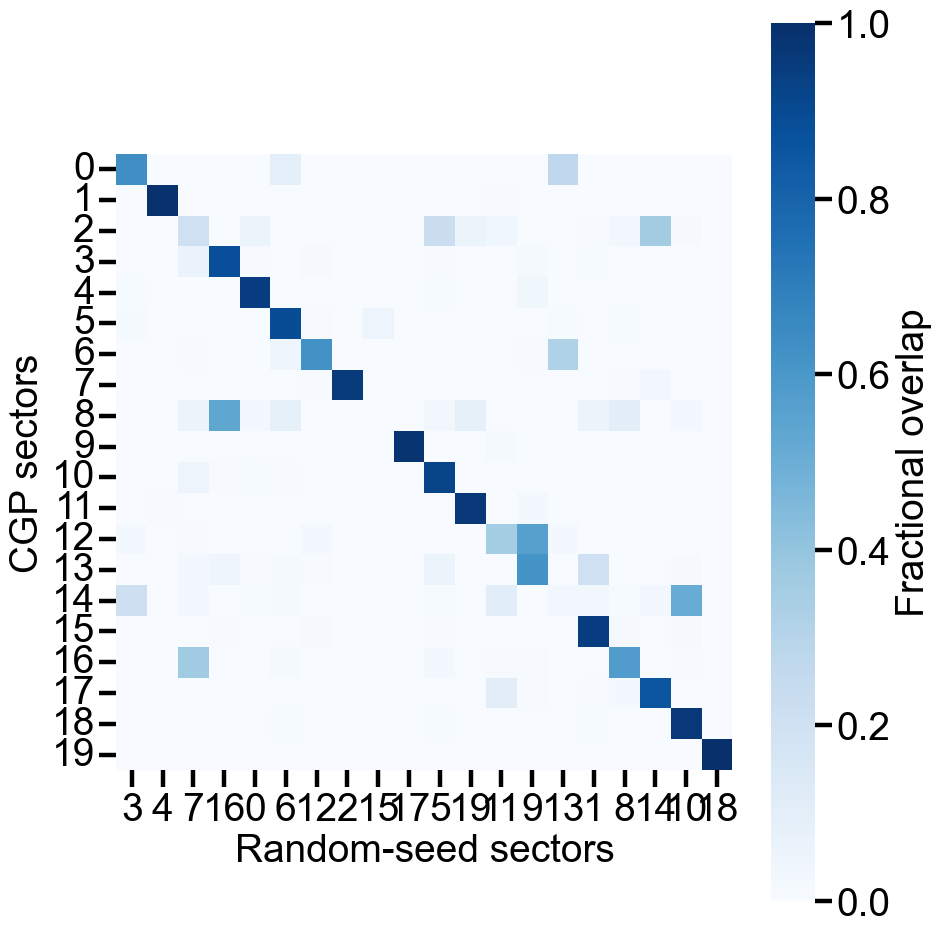

In [3]:
set_panel_style(scale=4)

def invert_clusters(cluster_dict):
    return {
        node: cluster
        for cluster, nodes in cluster_dict.items()
        for node in nodes
    }

inv1 = invert_clusters(clustered_nodes)
inv2 = invert_clusters(clustered_nodes2)

common_nodes = sorted(set(inv1) & set(inv2))
labels1 = [inv1[node] for node in common_nodes]
labels2 = [inv2[node] for node in common_nodes]

print(f"NMI = {normalized_mutual_info_score(labels1, labels2):.3f}")

conf_mat = pd.crosstab(
    pd.Series(labels1, name="CGP sectors"),
    pd.Series(labels2, name="Random-seed sectors")
)

row_idx, col_idx = linear_sum_assignment(-conf_mat.to_numpy())

matched_cols = [
    conf_mat.columns[col]
    for row, col in sorted(zip(row_idx, col_idx))
]

remaining_cols = [
    col for col in conf_mat.columns
    if col not in matched_cols
]

conf_mat = conf_mat[matched_cols + remaining_cols]
overlap = conf_mat.div(conf_mat.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 10))

sns.heatmap(
    overlap,
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    ax=ax,
    xticklabels=overlap.columns,
    yticklabels=overlap.index,
    cbar_kws={"label": "Fractional overlap"}
)

ax.set_xlabel("Random-seed sectors")
ax.set_ylabel("CGP sectors")

ax.set_xticks(np.arange(len(overlap.columns)) + 0.5)
ax.set_yticks(np.arange(len(overlap.index)) + 0.5)

ax.set_xticklabels(overlap.columns, rotation=0)
ax.set_yticklabels(overlap.index, rotation=0)

plt.tight_layout()
#plt.savefig("Supp_Figure5_sector_compare.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()